# Пятая лабораторная работа. Очистка данных

**Цель:** выполнить очистку погодных данных и подготовить их для дальнейшего обучения модели, прогнозирующей дождь на следующий день.

**Главное методическое решение:** целевая переменная `ДождьЗавтра` не заполняется модой. Строки, где правильный ответ неизвестен, исключаются до подготовки признаков. Для предотвращения утечки данных выборка делится на обучающую и тестовую части **до вычисления медиан и мод**. Все заполнители вычисляются только по обучающей части, а затем применяются к обеим частям.

В работе выполнены обязательная часть, базовый, средний и повышенный уровни. После каждого блока кода приведено объяснение результата.

In [37]:
import subprocess
import warnings
from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.exceptions import ConvergenceWarning

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
plt.style.use('ggplot')
warnings.filterwarnings('ignore', category=ConvergenceWarning)

repo_dir = Path('OA')
if not (repo_dir / 'weatherAUS.csv').exists():
    subprocess.run(
        ['git', 'clone', '--depth', '1', 'https://github.com/LoreOfMetal11/OA.git'],
        check=True
    )

## Теоретическая часть

### 1. Очистка данных

Очистка данных - это обнаружение и исправление либо удаление неполных, ошибочных, противоречивых, дублирующихся и несущественных записей. В прикладном искусственном интеллекте качество входной таблицы определяет качество закономерностей, которым обучится модель. Пропуски могут сделать обучение некоторых алгоритмов невозможным, дубликаты искусственно увеличивают вес отдельных наблюдений, а неправильные значения и выбросы искажают статистики и масштабирование. Поэтому очистка необходима до кодирования, масштабирования и обучения модели.

### 2. Типы пропусков

- **MCAR** - пропуск полностью случаен и не связан ни с самим отсутствующим значением, ни с другими признаками.
- **MAR** - вероятность пропуска объясняется другими наблюдаемыми признаками.
- **MNAR** - вероятность пропуска связана с самим отсутствующим значением или ненаблюдаемой причиной.

### 3. Удаление и заполнение

При удалении строк наблюдение исключается полностью. Это простой подход, но он сокращает объём данных и может изменить распределение выборки. При заполнении строка сохраняется, а пропуск заменяется статистикой, интерполяцией или оценкой модели. Заполнение сохраняет больше наблюдений, но добавляет оценочные, а не реально измеренные значения.

### 4. Среднее и медиана

Среднее разумно использовать для примерно симметричных данных без сильных выбросов. Медиана устойчивее к асимметрии и экстремальным наблюдениям, поэтому для погодных числовых признаков в финальном простом решении выбрана медиана. В задаче машинного обучения медианы и моды необходимо вычислять только на обучающей части.

### 5. Риски неправильной очистки

Ошибочная очистка может удалить реальные редкие события, сохранить ошибки измерений, исказить баланс классов, уменьшить дисперсию, создать ложные корреляции или вызвать утечку данных. Особенно опасно заполнять неизвестную целевую переменную модой: так в таблице появляются искусственные правильные ответы. Поэтому строки без `ДождьЗавтра` будут удалены, а сам целевой столбец останется неизменным.

## Загрузка и описание данных

In [38]:
data = pd.read_csv(repo_dir / 'weatherAUS.csv')

columns_ru = {
    'Date': 'Дата', 'Location': 'Место',
    'MinTemp': 'МинТемпература', 'MaxTemp': 'МаксТемпература',
    'Rainfall': 'Осадки', 'Evaporation': 'Испарение',
    'Sunshine': 'СолнечныеЧасы',
    'WindGustDir': 'НаправлениеПорываВетра',
    'WindGustSpeed': 'СкоростьПорываВетра',
    'WindDir9am': 'НаправлениеВетра9',
    'WindDir3pm': 'НаправлениеВетра15',
    'WindSpeed9am': 'СкоростьВетра9',
    'WindSpeed3pm': 'СкоростьВетра15',
    'Humidity9am': 'Влажность9', 'Humidity3pm': 'Влажность15',
    'Pressure9am': 'Давление9', 'Pressure3pm': 'Давление15',
    'Cloud9am': 'Облачность9', 'Cloud3pm': 'Облачность15',
    'Temp9am': 'Температура9', 'Temp3pm': 'Температура15',
    'RainToday': 'ДождьСегодня', 'RainTomorrow': 'ДождьЗавтра'
}

data = data.rename(columns=columns_ru)
data['Дата'] = pd.to_datetime(data['Дата'], errors='coerce')
data.sample(5)

,Дата,Место,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,НаправлениеПорываВетра,СкоростьПорываВетра,НаправлениеВетра9,НаправлениеВетра15,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15,ДождьСегодня,ДождьЗавтра
42000,2015-12-27,Williamtown,17.600,21.600,43.000,NaN,NaN,SSW,52.000,S,S,26.000,33.000,82.000,58.000,1015.700,1017.900,8.000,8.000,18.700,21.500,Yes,No
102418,2017-02-11,MountGambier,15.200,24.300,0.000,NaN,NaN,SW,39.000,SSE,SW,9.000,19.000,70.000,58.000,1010.800,1010.100,8.000,8.000,18.200,20.900,No,Yes
9909,2011-06-01,CoffsHarbour,13.600,20.100,36.800,6.800,2.200,S,76.000,ESE,S,35.000,41.000,81.000,77.000,1017.300,1016.300,7.000,7.000,16.400,19.000,Yes,Yes
44256,2013-11-03,Wollongong,19.500,34.400,0.000,NaN,NaN,S,63.000,NW,SSE,30.000,46.000,28.000,78.000,1009.400,1007.700,NaN,NaN,26.000,20.500,No,No
116272,2013-10-08,PearceRAAF,10.600,24.900,0.000,NaN,7.300,W,48.000,N,WNW,24.000,19.000,64.000,75.000,1010.800,1009.600,4.000,7.000,20.100,19.500,No,Yes


 Каждая строка описывает погодные условия в конкретном городе Австралии за определённую дату. Названия столбцов переведены для единообразия с предыдущей лабораторной. Дата сразу преобразована в `datetime`, потому что это не обычная текстовая категория. Целевая переменная - `ДождьЗавтра`, принимающая значения `Yes` и `No`.

In [39]:
print('Размер исходной таблицы:', data.shape)
print('\nТипы столбцов:')
print(data.dtypes)

Размер исходной таблицы: (145460, 23)

Типы столбцов:
Дата                      datetime64[ns]
Место                             object
МинТемпература                   float64
МаксТемпература                  float64
Осадки                           float64
Испарение                        float64
СолнечныеЧасы                    float64
НаправлениеПорываВетра            object
СкоростьПорываВетра              float64
НаправлениеВетра9                 object
НаправлениеВетра15                object
СкоростьВетра9                   float64
СкоростьВетра15                  float64
Влажность9                       float64
Влажность15                      float64
Давление9                        float64
Давление15                       float64
Облачность9                      float64
Облачность15                     float64
Температура9                     float64
Температура15                    float64
ДождьСегодня                      object
ДождьЗавтра                       object
dty

 Исходная таблица содержит 145 460 строк и 23 столбца. В ней присутствуют числовые измерения, текстовые категории и одна дата. Типы данных соответствуют смыслу показателей: температуры и другие измерения являются числами, направления ветра и ответы о дожде - строками.

In [40]:
target_col = 'ДождьЗавтра'
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
category_cols = data.select_dtypes(include='object').columns.tolist()
feature_category_cols = [col for col in category_cols if col != target_col]
date_cols = data.select_dtypes(include=['datetime', 'datetimetz']).columns.tolist()

print(f'Числовые признаки ({len(numeric_cols)}):', numeric_cols)
print(f'\nКатегориальные входные признаки ({len(feature_category_cols)}):', feature_category_cols)
print(f'\nЦелевая переменная: {target_col}')
print(f'\nПризнаки даты ({len(date_cols)}):', date_cols)

Числовые признаки (16): ['МинТемпература', 'МаксТемпература', 'Осадки', 'Испарение', 'СолнечныеЧасы', 'СкоростьПорываВетра', 'СкоростьВетра9', 'СкоростьВетра15', 'Влажность9', 'Влажность15', 'Давление9', 'Давление15', 'Облачность9', 'Облачность15', 'Температура9', 'Температура15']

Категориальные входные признаки (5): ['Место', 'НаправлениеПорываВетра', 'НаправлениеВетра9', 'НаправлениеВетра15', 'ДождьСегодня']

Целевая переменная: ДождьЗавтра

Признаки даты (1): ['Дата']


 Получено 16 числовых входных признаков, 5 категориальных входных признаков, одна дата и одна целевая переменная. `ДождьЗавтра` намеренно исключён из списка категорий, которые можно заполнять модой. Это предотвращает создание выдуманных меток класса.

## 2.1. Базовый уровень

### Поиск пропусков

In [41]:
missing_before = pd.DataFrame({
    'Количество': data.isna().sum(),
    'Доля, %': data.isna().mean() * 100
}).sort_values('Доля, %', ascending=False)
missing_before

,Количество,"Доля, %"
СолнечныеЧасы,69835,48.010
Испарение,62790,43.167
Облачность15,59358,40.807
Облачность9,55888,38.422
Давление9,15065,10.357
Давление15,15028,10.331
НаправлениеВетра9,10566,7.264
НаправлениеПорываВетра,10326,7.099
СкоростьПорываВетра,10263,7.056
Влажность15,4507,3.098


 Наибольшее количество пропусков находится в солнечных часах, испарении и облачности. В целевой переменной `ДождьЗавтра` отсутствуют 3 267 значений. Эти строки нельзя размечать как `No` только потому, что данный класс встречается чаще: фактическая погода неизвестна. Поэтому целевые пропуски удаляются, а пропуски входных признаков будут заполнены позднее.

### Целевая переменная

In [42]:
rows_before_target = len(data)
model_data = data.dropna(subset=[target_col]).copy()

print('Строк до удаления неизвестной цели:', rows_before_target)
print('Удалено строк:', rows_before_target - len(model_data))
print('Строк с известной целью:', len(model_data))
print('\nРаспределение целевой переменной:')
print(model_data[target_col].value_counts())

Строк до удаления неизвестной цели: 145460
Удалено строк: 3267
Строк с известной целью: 142193

Распределение целевой переменной:
ДождьЗавтра
No     110316
Yes     31877
Name: count, dtype: int64


 Удалены 3 267 строк, в которых неизвестно, был ли дождь на следующий день. Осталось 142 193 наблюдения с настоящими метками: 110 316 объектов класса `No` и 31 877 объектов класса `Yes`. Целевая переменная не была заполнена и не была изменена.

### Минимумы и максимумы

In [43]:
min_max = pd.DataFrame({
    'Минимум': model_data[numeric_cols].min(),
    'Максимум': model_data[numeric_cols].max()
})
min_max

,Минимум,Максимум
МинТемпература,-8.500,33.900
МаксТемпература,-4.800,48.100
Осадки,0.000,371.000
Испарение,0.000,145.000
СолнечныеЧасы,0.000,14.500
СкоростьПорываВетра,6.000,135.000
СкоростьВетра9,0.000,130.000
СкоростьВетра15,0.000,87.000
Влажность9,0.000,100.000
Влажность15,0.000,100.000


 Температуры, влажность, давление, осадки и скорости ветра находятся в правдоподобных широких границах. Однако максимальное значение облачности равно 9, тогда как используемая шкала облачности в октах имеет диапазон от 0 до 8. Поэтому значения 9 рассматриваются как очевидно некорректные. Редкие сильные осадки и ветер не удаляются только из-за статистической необычности: они могут быть реальными погодными событиями.

### Допустимые диапазоны

In [44]:
valid_ranges = {
    'МинТемпература': (-50, 50), 'МаксТемпература': (-50, 60),
    'Осадки': (0, 500), 'Испарение': (0, 150),
    'СолнечныеЧасы': (0, 24), 'СкоростьПорываВетра': (0, 200),
    'СкоростьВетра9': (0, 150), 'СкоростьВетра15': (0, 150),
    'Влажность9': (0, 100), 'Влажность15': (0, 100),
    'Давление9': (850, 1100), 'Давление15': (850, 1100),
    'Облачность9': (0, 8), 'Облачность15': (0, 8),
    'Температура9': (-50, 60), 'Температура15': (-50, 60)
}

invalid_mask = pd.Series(False, index=model_data.index)
range_rows = []

for col, (lower, upper) in valid_ranges.items():
    current_mask = model_data[col].notna() & ~model_data[col].between(lower, upper)
    invalid_mask |= current_mask
    range_rows.append({
        'Признак': col,
        'Нижняя граница': lower,
        'Верхняя граница': upper,
        'Некорректных значений': current_mask.sum()
    })

range_report = pd.DataFrame(range_rows).set_index('Признак')
range_report

,Нижняя граница,Верхняя граница,Некорректных значений
Признак,,,
МинТемпература,-50,50,0
МаксТемпература,-50,60,0
Осадки,0,500,0
Испарение,0,150,0
СолнечныеЧасы,0,24,0
СкоростьПорываВетра,0,200,0
СкоростьВетра9,0,150,0
СкоростьВетра15,0,150,0
Влажность9,0,100,0


 Нарушения обнаружены только у облачности: два значения в `Облачность9` и одно значение в `Облачность15` равны 9. Проверка выполнялась только для непустых ячеек, поэтому `NaN` не были ошибочно объявлены выбросами. Границы заданы явно и могут быть повторно применены к новым данным.

In [45]:
rows_before_ranges = len(model_data)
model_data = model_data.loc[~invalid_mask].copy()

print('Удалено строк с некорректными диапазонами:', rows_before_ranges - len(model_data))
print('Размер после проверки диапазонов:', model_data.shape)

Удалено строк с некорректными диапазонами: 3
Размер после проверки диапазонов: (142190, 23)


 Удалены только 3 строки с очевидно некорректной облачностью. После этого осталось 142 190 строк. Такой подход мягче автоматического удаления всех статистических выбросов по IQR и сохраняет редкие реальные погодные события.

### Дубликаты

In [46]:
duplicates_before = model_data.duplicated().sum()
model_data = model_data.drop_duplicates().reset_index(drop=True)

print('Полных дубликатов найдено:', duplicates_before)
print('Полных дубликатов после очистки:', model_data.duplicated().sum())
print('Текущий размер:', model_data.shape)

Полных дубликатов найдено: 0
Полных дубликатов после очистки: 0
Текущий размер: (142190, 23)


 Полных дубликатов не обнаружено, поэтому размер таблицы не изменился. Тем не менее операция `drop_duplicates()` оставлена в конвейере: если исходный файл обновится, повторяющиеся записи будут удалены автоматически.

### Разделение выборки

In [47]:
train_raw, test_raw = train_test_split(
    model_data,
    test_size=0.20,
    random_state=42,
    stratify=model_data[target_col]
)

train_raw = train_raw.copy()
test_raw = test_raw.copy()

print('Обучающая часть:', train_raw.shape)
print('Тестовая часть:', test_raw.shape)
print('\nДоли классов в полной, обучающей и тестовой частях:')
print(pd.DataFrame({
    'Полная': model_data[target_col].value_counts(normalize=True),
    'Обучающая': train_raw[target_col].value_counts(normalize=True),
    'Тестовая': test_raw[target_col].value_counts(normalize=True)
}))

Обучающая часть: (113752, 23)
Тестовая часть: (28438, 23)

Доли классов в полной, обучающей и тестовой частях:
             Полная  Обучающая  Тестовая
ДождьЗавтра                             
No            0.776      0.776     0.776
Yes           0.224      0.224     0.224


 Выборка разделена в отношении 80/20: 113 752 строки направлены в обучающую часть и 28 438 - в тестовую. `random_state=42` обеспечивает повторяемость результата. Стратификация сохраняет примерно одинаковую долю классов `Yes` и `No` в обеих частях. Разделение выполнено до расчёта заполнителей, поэтому статистики тестовой части не участвуют в подготовке обучающих данных.

### Простое заполнение

In [48]:
train_clean = train_raw.copy()
test_clean = test_raw.copy()

numeric_fill_values = train_raw[numeric_cols].median()
train_clean[numeric_cols] = train_clean[numeric_cols].fillna(numeric_fill_values)
test_clean[numeric_cols] = test_clean[numeric_cols].fillna(numeric_fill_values)

category_fill_values = {
    col: train_raw[col].mode(dropna=True).iloc[0]
    for col in feature_category_cols
}
train_clean[feature_category_cols] = train_clean[feature_category_cols].fillna(category_fill_values)
test_clean[feature_category_cols] = test_clean[feature_category_cols].fillna(category_fill_values)

fill_values_table = pd.concat([
    numeric_fill_values.rename('Заполнитель').to_frame().assign(Метод='медиана'),
    pd.Series(category_fill_values, name='Заполнитель').to_frame().assign(Метод='мода')
])
fill_values_table

,Заполнитель,Метод
МинТемпература,12.000,медиана
МаксТемпература,22.600,медиана
Осадки,0.000,медиана
Испарение,4.800,медиана
СолнечныеЧасы,8.500,медиана
СкоростьПорываВетра,39.000,медиана
СкоростьВетра9,13.000,медиана
СкоростьВетра15,19.000,медиана
Влажность9,70.000,медиана
Влажность15,52.000,медиана


 Использован наиболее простой и устойчивый вариант: числовые признаки заполнены медианой, категориальные входные признаки - модой. Все значения рассчитаны только на `train_raw`; тестовая часть получила те же готовые заполнители. Целевая переменная отсутствует в `feature_category_cols`, поэтому код физически не может заменить её модой. Такой порядок ближе к реальному обучению модели и исключает утечку статистик из тестовой части.

### Контроль уровня 1

In [49]:
def check_quality(df, name):
    range_errors = sum(
        (~df[col].between(lower, upper)).sum()
        for col, (lower, upper) in valid_ranges.items()
    )
    return {
        'Набор': name,
        'Строк': len(df),
        'Пропусков': df.isna().sum().sum(),
        'Дубликатов': df.duplicated().sum(),
        'Нарушений диапазонов': range_errors,
        'Неизвестных целей': df[target_col].isna().sum()
    }

quality = pd.DataFrame([
    check_quality(train_clean, 'Обучающий'),
    check_quality(test_clean, 'Тестовый')
]).set_index('Набор')
quality

,Строк,Пропусков,Дубликатов,Нарушений диапазонов,Неизвестных целей
Набор,,,,,
Обучающий,113752,0,0,0,0
Тестовый,28438,0,0,0,0


 В обучающей и тестовой частях нет пропусков и значений за установленными диапазонами. Неизвестные целевые метки отсутствуют. Полные дубликаты проверялись до разбиения, поэтому один объект не может одновременно оказаться в обучающей и тестовой части. Базовый уровень выполнен, а данные готовы к кодированию и масштабированию.

## 2.2. Сравнение стратегий

### Среднее и интерполяция

In [50]:
comparison_col = 'СолнечныеЧасы'
source = train_raw[comparison_col]

filled_mean = source.fillna(source.mean())

ordered_train = train_raw.sort_values(['Место', 'Дата']).copy()
filled_interpolation = ordered_train.groupby('Место')[comparison_col].transform(
    lambda values: values.interpolate(method='linear', limit_direction='both')
)
filled_interpolation = filled_interpolation.reindex(train_raw.index)
filled_interpolation = filled_interpolation.fillna(source.median())

strategy_comparison = pd.DataFrame({
    'До заполнения': source.describe(),
    'Среднее': filled_mean.describe(),
    'Интерполяция': filled_interpolation.describe()
})
strategy_comparison.loc['Асимметрия'] = [
    source.skew(), filled_mean.skew(), filled_interpolation.skew()
]
strategy_comparison.loc['Пропуски'] = [
    source.isna().sum(), filled_mean.isna().sum(), filled_interpolation.isna().sum()
]
strategy_comparison

,До заполнения,Среднее,Интерполяция
count,59391.000,113752.000,113752.000
mean,7.623,7.623,7.771
std,3.778,2.730,3.058
min,0.000,0.000,0.000
25%,4.900,7.623,6.700
50%,8.500,7.623,8.500
75%,10.600,8.700,9.100
max,14.500,14.500,14.500
Асимметрия,-0.504,-0.697,-0.860
Пропуски,54361.000,0.000,0.000


 Оба метода полностью устраняют пропуски. Среднее сохраняет исходное среднее арифметическое, но создаёт много одинаковых значений и уменьшает стандартное отклонение. Интерполяция использует соседние по дате наблюдения той же локации и лучше сохраняет изменчивость. Для последующего масштабирования интерполяция выглядит естественнее, однако она сложнее и зависит от порядка строк. Для финального простого решения оставлена медиана, потому что она легко объясняется и воспроизводится.

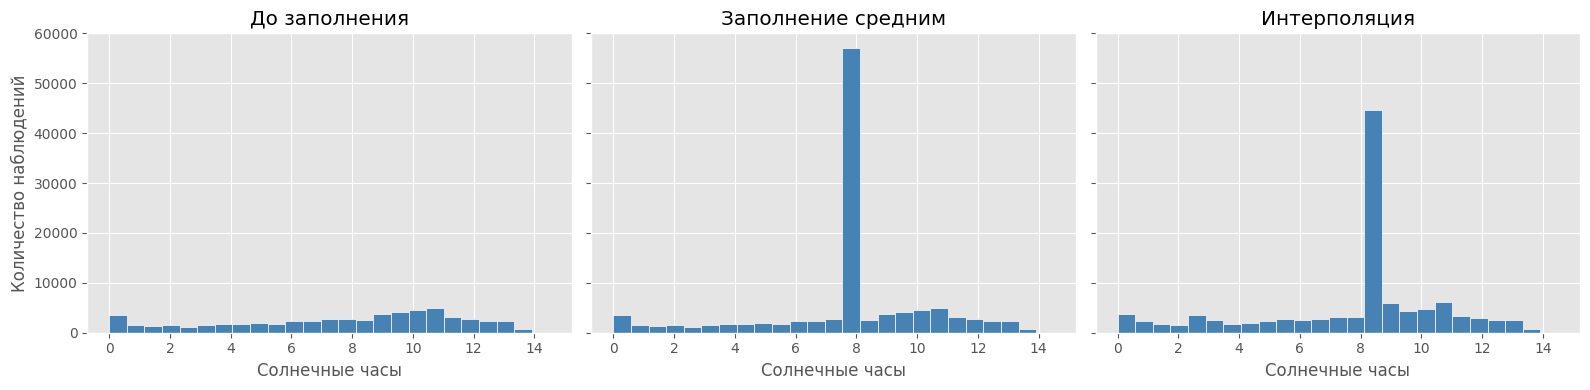

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
values = [source.dropna(), filled_mean, filled_interpolation]
titles = ['До заполнения', 'Заполнение средним', 'Интерполяция']

for ax, current_values, title in zip(axes, values, titles):
    ax.hist(current_values, bins=25, color='steelblue', edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel('Солнечные часы')
axes[0].set_ylabel('Количество наблюдений')
plt.tight_layout()
plt.show()

 На графике заполнение средним проявляется как высокий искусственный столбец около среднего значения. После интерполяции значения распределяются по диапазону более плавно. Это подтверждает, что одно массовое значение сжимает распределение сильнее, чем восстановление по соседним наблюдениям.

### Категории до и после

In [52]:
category_summary = []
for col in feature_category_cols:
    category_summary.append({
        'Признак': col,
        'Пропусков до': train_raw[col].isna().sum(),
        'Уникальных до без NaN': train_raw[col].nunique(dropna=True),
        'Пропусков после': train_clean[col].isna().sum(),
        'Уникальных после': train_clean[col].nunique(dropna=True),
        'Заполнитель': category_fill_values[col]
    })

pd.DataFrame(category_summary).set_index('Признак')

,Пропусков до,Уникальных до без NaN,Пропусков после,Уникальных после,Заполнитель
Признак,,,,,
Место,0,49,0,49,Canberra
НаправлениеПорываВетра,7477,16,0,16,W
НаправлениеВетра9,8011,16,0,16,N
НаправлениеВетра15,3062,16,0,16,SE
ДождьСегодня,1124,2,0,2,No


 Пропуски во всех категориальных **входных** признаках исчезли, а новых категорий не появилось. Для каждого столбца использована его обучающая мода. Число уникальных реальных категорий сохранилось, но частота модальной категории увеличилась. `ДождьЗавтра` в таблицу заполнителей не входит и в этом блоке не изменяется.

In [53]:
print('Целевая переменная до заполнения входных признаков:')
print(train_raw[target_col].value_counts(dropna=False))
print('\nЦелевая переменная после заполнения входных признаков:')
print(train_clean[target_col].value_counts(dropna=False))
print('\nЦель полностью совпадает:', train_raw[target_col].equals(train_clean[target_col]))

Целевая переменная до заполнения входных признаков:
ДождьЗавтра
No     88250
Yes    25502
Name: count, dtype: int64

Целевая переменная после заполнения входных признаков:
ДождьЗавтра
No     88250
Yes    25502
Name: count, dtype: int64

Цель полностью совпадает: True


 Распределение `ДождьЗавтра` до и после заполнения входных признаков полностью совпадает. Это отдельная контрольная проверка, подтверждающая, что целевая переменная не заполнялась и не редактировалась.

## 2.3. Одномерное и многомерное восстановление

### 2.3.1. Исходная описательная статистика числовых признаков

In [93]:
def describe_all(df):
    statistics = {}

    for col in numeric_cols:
        series = df[col]

        statistics[col] = {
            'Количество': series.count(),
            'Среднее': series.mean(),
            'Стандартное отклонение': series.std(),
            'Минимум': series.min(),
            '25%': series.quantile(0.25),
            'Медиана': series.median(),
            '75%': series.quantile(0.75),
            'Максимум': series.max(),
            'Асимметрия': series.skew(),
            'Пропуски': series.isna().sum()
        }

    return pd.DataFrame.from_dict(statistics, orient='index')


print('TRAIN - до восстановления:')
display(describe_all(train_raw))

print('TEST - до восстановления:')
display(describe_all(test_raw))

TRAIN - до восстановления:


,Количество,Среднее,Стандартное отклонение,Минимум,25%,Медиана,75%,Максимум,Асимметрия,Пропуски
МинТемпература,113241,12.168,6.414,-8.500,7.600,12.000,16.800,31.900,0.023,511
МаксТемпература,113487,23.216,7.122,-4.800,17.900,22.600,28.200,48.100,0.224,265
Осадки,112628,2.358,8.554,0.000,0.000,0.000,0.800,371.000,10.129,1124
Испарение,65031,5.476,4.186,0.000,2.600,4.800,7.400,145.000,3.772,48721
СолнечныеЧасы,59391,7.623,3.778,0.000,4.900,8.500,10.600,14.500,-0.504,54361
СкоростьПорываВетра,106321,39.952,13.570,6.000,31.000,39.000,48.000,135.000,0.876,7431
СкоростьВетра9,112659,13.985,8.871,0.000,7.000,13.000,19.000,130.000,0.766,1093
СкоростьВетра15,111613,18.624,8.784,0.000,13.000,19.000,24.000,87.000,0.625,2139
Влажность9,112334,68.856,19.056,0.000,57.000,70.000,83.000,100.000,-0.487,1418
Влажность15,110867,51.488,20.803,0.000,37.000,52.000,66.000,100.000,0.034,2885


TEST - до восстановления:


,Количество,Среднее,Стандартное отклонение,Минимум,25%,Медиана,75%,Максимум,Асимметрия,Пропуски
МинТемпература,28312,12.262,6.362,-8.000,7.700,12.100,16.900,33.900,0.029,126
МаксТемпература,28381,23.271,7.101,-3.200,18.000,22.600,28.300,47.300,0.230,57
Осадки,28156,2.318,8.101,0.000,0.000,0.000,0.800,236.800,8.713,282
Испарение,16317,5.445,4.199,0.000,2.600,4.600,7.400,81.200,3.649,12121
СолнечныеЧасы,14983,7.632,3.795,0.000,4.800,8.500,10.700,14.000,-0.500,13455
СкоростьПорываВетра,26600,40.113,13.665,7.000,31.000,39.000,48.000,130.000,0.866,1838
СкоростьВетра9,28183,14.069,8.980,0.000,7.000,13.000,19.000,83.000,0.813,255
СкоростьВетра15,27947,18.693,8.880,0.000,13.000,19.000,24.000,83.000,0.657,491
Влажность9,28082,68.795,19.031,1.000,57.000,70.000,83.000,100.000,-0.465,356
Влажность15,27713,51.463,20.777,1.000,37.000,52.000,66.000,100.000,0.037,725


Таблицы показывают статистики всех 16 числовых признаков до восстановления отдельно для train и test. Количество известных значений различается между признаками, что указывает на пропуски. Например, в train для солнечных часов известны 59 391 значения из 113 752, то есть отсутствуют 54 361 значения. Среднее этого признака равно 7,623, стандартное отклонение - 3,778, медиана - 8,500. Эти показатели служат исходной точкой для сравнения, но рассчитаны только по наблюдаемым значениям.


### 2.3.2. Одномерное восстановление медианой


In [90]:
simple_imputer = SimpleImputer(strategy='median')

simple_imputer.fit(train_raw[numeric_cols])

simple_train = pd.DataFrame(
    simple_imputer.transform(train_raw[numeric_cols]),
    columns=numeric_cols,
    index=train_raw.index
)

simple_test = pd.DataFrame(
    simple_imputer.transform(test_raw[numeric_cols]),
    columns=numeric_cols,
    index=test_raw.index
)

print('TRAIN - после одномерного восстановления:')
display(describe_all(simple_train))

print('TEST - после одномерного восстановления:')
display(describe_all(simple_test))

TRAIN - после одномерного восстановления:


,Количество,Среднее,Стандартное отклонение,Минимум,25%,Медиана,75%,Максимум,Асимметрия,Пропуски
МинТемпература,113752,12.167,6.399,-8.500,7.600,12.000,16.800,31.900,0.023,0
МаксТемпература,113752,23.214,7.114,-4.800,17.900,22.600,28.200,48.100,0.224,0
Осадки,113752,2.335,8.515,0.000,0.000,0.000,0.600,371.000,10.176,0
Испарение,113752,5.186,3.183,0.000,4.000,4.800,5.400,145.000,5.176,0
СолнечныеЧасы,113752,8.042,2.765,0.000,8.200,8.500,8.700,14.500,-1.114,0
СкоростьПорываВетра,113752,39.890,13.121,6.000,31.000,39.000,46.000,135.000,0.920,0
СкоростьВетра9,113752,13.976,8.829,0.000,7.000,13.000,19.000,130.000,0.772,0
СкоростьВетра15,113752,18.631,8.701,0.000,13.000,19.000,24.000,87.000,0.628,0
Влажность9,113752,68.871,18.937,0.000,57.000,70.000,83.000,100.000,-0.493,0
Влажность15,113752,51.501,20.538,0.000,37.000,52.000,65.000,100.000,0.032,0


TEST - после одномерного восстановления:


,Количество,Среднее,Стандартное отклонение,Минимум,25%,Медиана,75%,Максимум,Асимметрия,Пропуски
МинТемпература,28438,12.261,6.347,-8.000,7.700,12.000,16.800,33.900,0.030,0
МаксТемпература,28438,23.269,7.094,-3.200,18.000,22.600,28.200,47.300,0.231,0
Осадки,28438,2.295,8.064,0.000,0.000,0.000,0.600,236.800,8.755,0
Испарение,28438,5.170,3.196,0.000,4.000,4.800,5.200,81.200,5.000,0
СолнечныеЧасы,28438,8.043,2.789,0.000,8.200,8.500,8.800,14.000,-1.095,0
СкоростьПорываВетра,28438,40.042,13.218,7.000,31.000,39.000,46.000,130.000,0.911,0
СкоростьВетра9,28438,14.059,8.940,0.000,7.000,13.000,19.000,83.000,0.820,0
СкоростьВетра15,28438,18.699,8.803,0.000,13.000,19.000,24.000,83.000,0.661,0
Влажность9,28438,68.810,18.912,1.000,57.000,70.000,83.000,100.000,-0.471,0
Влажность15,28438,51.476,20.511,1.000,37.000,52.000,65.000,100.000,0.035,0


SimpleImputer обучен только на train и затем применён к обеим частям через transform. После заполнения количество значений каждого числового признака составляет 113 752 в train и 28 438 в test, пропуски отсутствуют. Для солнечных часов в train медианное заполнение изменило среднее с 7,623 до 8,042 и уменьшило стандартное отклонение с 3,778 до 2,765. Следовательно, заполнение одной медианой заметно сжимает разброс этого признака, хотя сохраняет его медиану.


### 2.3.3. Многомерное восстановление признаков


In [87]:
iterative_imputer = IterativeImputer(
    max_iter=5,
    random_state=42,
    initial_strategy='median',
    skip_complete=True,
    min_value=train_raw[numeric_cols].min().to_numpy(),
    max_value=train_raw[numeric_cols].max().to_numpy()
)

iterative_imputer.fit(train_raw[numeric_cols])

iterative_train = pd.DataFrame(
    iterative_imputer.transform(train_raw[numeric_cols]),
    columns=numeric_cols,
    index=train_raw.index
)

iterative_test = pd.DataFrame(
    iterative_imputer.transform(test_raw[numeric_cols]),
    columns=numeric_cols,
    index=test_raw.index
)

print('TRAIN - после многомерного восстановления:')
display(describe_all(iterative_train))

print('TEST - после многомерного восстановления:')
display(describe_all(iterative_test))

TRAIN — до восстановления:


,Количество,Среднее,Стандартное отклонение,Минимум,25%,Медиана,75%,Максимум,Асимметрия,Пропуски
МинТемпература,113241,12.168,6.414,-8.500,7.600,12.000,16.800,31.900,0.023,511
МаксТемпература,113487,23.216,7.122,-4.800,17.900,22.600,28.200,48.100,0.224,265
Осадки,112628,2.358,8.554,0.000,0.000,0.000,0.800,371.000,10.129,1124
Испарение,65031,5.476,4.186,0.000,2.600,4.800,7.400,145.000,3.772,48721
СолнечныеЧасы,59391,7.623,3.778,0.000,4.900,8.500,10.600,14.500,-0.504,54361
СкоростьПорываВетра,106321,39.952,13.570,6.000,31.000,39.000,48.000,135.000,0.876,7431
СкоростьВетра9,112659,13.985,8.871,0.000,7.000,13.000,19.000,130.000,0.766,1093
СкоростьВетра15,111613,18.624,8.784,0.000,13.000,19.000,24.000,87.000,0.625,2139
Влажность9,112334,68.856,19.056,0.000,57.000,70.000,83.000,100.000,-0.487,1418
Влажность15,110867,51.488,20.803,0.000,37.000,52.000,66.000,100.000,0.034,2885


TEST — до восстановления:


,Количество,Среднее,Стандартное отклонение,Минимум,25%,Медиана,75%,Максимум,Асимметрия,Пропуски
МинТемпература,28312,12.262,6.362,-8.000,7.700,12.100,16.900,33.900,0.029,126
МаксТемпература,28381,23.271,7.101,-3.200,18.000,22.600,28.300,47.300,0.230,57
Осадки,28156,2.318,8.101,0.000,0.000,0.000,0.800,236.800,8.713,282
Испарение,16317,5.445,4.199,0.000,2.600,4.600,7.400,81.200,3.649,12121
СолнечныеЧасы,14983,7.632,3.795,0.000,4.800,8.500,10.700,14.000,-0.500,13455
СкоростьПорываВетра,26600,40.113,13.665,7.000,31.000,39.000,48.000,130.000,0.866,1838
СкоростьВетра9,28183,14.069,8.980,0.000,7.000,13.000,19.000,83.000,0.813,255
СкоростьВетра15,27947,18.693,8.880,0.000,13.000,19.000,24.000,83.000,0.657,491
Влажность9,28082,68.795,19.031,1.000,57.000,70.000,83.000,100.000,-0.465,356
Влажность15,27713,51.463,20.777,1.000,37.000,52.000,66.000,100.000,0.037,725


IterativeImputer также обучается только на train; восстановленные значения возвращаются в DataFrame с исходными индексами. После преобразования числовые пропуски отсутствуют в обеих частях. Для солнечных часов в train получены среднее 7,424 и стандартное отклонение 3,450. Разброс этого признака ближе к исходному, чем после медианного заполнения, однако медиана меняется. Поэтому преимущество многомерного восстановления зависит от того, какие статистики включены в критерий сравнения.


### 2.3.4. Восстановление методом интерполяции


In [69]:
train_interpolation = train_raw.copy()
test_interpolation = test_raw.copy()

for col in numeric_cols:
    median = train_raw[col].median()

    for location, group in train_raw.groupby('Место'):
        known = (
            group.dropna(subset=[col])
            .groupby('Дата')[col]
            .mean()
            .sort_index()
        )

        if known.empty:
            continue

        known_dates = known.index.astype('int64').to_numpy()
        known_values = known.to_numpy()

        for df in [train_interpolation, test_interpolation]:
            missing = (
                (df['Место'] == location)
                & df[col].isna()
            )

            if missing.any():
                missing_dates = (
                    df.loc[missing, 'Дата']
                    .astype('int64')
                    .to_numpy()
                )

                df.loc[missing, col] = np.interp(
                    missing_dates,
                    known_dates,
                    known_values,
                    left=np.nan,
                    right=np.nan
                )

    train_interpolation[col] = (
        train_interpolation[col].fillna(median)
    )

    test_interpolation[col] = (
        test_interpolation[col].fillna(median)
    )


print('TRAIN - после интерполяции:')
display(describe_all(train_interpolation))

print('TEST - после интерполяции:')
display(describe_all(test_interpolation))

TRAIN — после интерполяции:


,Количество,Среднее,Стандартное отклонение,Минимум,25%,Медиана,75%,Максимум,Асимметрия,Пропуски
МинТемпература,113752,12.170,6.412,-8.500,7.600,12.000,16.800,31.900,0.021,0
МаксТемпература,113752,23.217,7.121,-4.800,17.900,22.600,28.200,48.100,0.223,0
Осадки,113752,2.380,8.562,0.000,0.000,0.000,0.800,371.000,10.064,0
Испарение,113752,5.153,3.787,0.000,3.200,4.800,5.800,145.000,4.546,0
СолнечныеЧасы,113752,7.771,3.058,0.000,6.700,8.500,9.100,14.500,-0.860,0
СкоростьПорываВетра,113752,40.009,13.211,6.000,31.000,39.000,48.000,135.000,0.885,0
СкоростьВетра9,113752,13.987,8.858,0.000,7.000,13.000,19.000,130.000,0.761,0
СкоростьВетра15,113752,18.842,9.024,0.000,13.000,19.000,24.000,87.000,0.665,0
Влажность9,113752,68.888,19.109,0.000,57.000,70.000,83.000,100.000,-0.494,0
Влажность15,113752,51.360,20.836,0.000,36.000,52.000,66.000,100.000,0.041,0


TEST — после интерполяции:


,Количество,Среднее,Стандартное отклонение,Минимум,25%,Медиана,75%,Максимум,Асимметрия,Пропуски
МинТемпература,28438,12.265,6.362,-8.000,7.700,12.100,16.900,33.900,0.026,0
МаксТемпература,28438,23.273,7.098,-3.200,18.000,22.600,28.300,47.300,0.230,0
Осадки,28438,2.325,8.088,0.000,0.000,0.000,0.800,236.800,8.692,0
Испарение,28438,5.226,4.137,0.000,3.400,4.800,5.800,81.200,5.105,0
СолнечныеЧасы,28438,7.791,3.018,0.000,6.700,8.500,9.250,14.000,-0.837,0
СкоростьПорываВетра,28438,40.144,13.329,7.000,31.000,39.000,48.000,130.000,0.889,0
СкоростьВетра9,28438,14.049,8.975,0.000,7.000,13.000,19.000,83.000,0.813,0
СкоростьВетра15,28438,18.690,8.870,0.000,13.000,19.000,24.000,83.000,0.645,0
Влажность9,28438,68.751,19.088,1.000,57.000,70.000,83.000,100.000,-0.476,0
Влажность15,28438,51.403,20.717,1.000,37.000,52.000,65.000,100.000,0.034,0


Интерполяция выполнена после сортировки по локации и дате, отдельно внутри каждой локации и каждой части выборки. Остаточные пропуски заполняются медианой train. Числовые пропуски устранены; для солнечных часов в train среднее равно 7,771, стандартное отклонение - 3,058, медиана - 8,500. По этому признаку интерполяция сохраняет разброс лучше медианного заполнения, но хуже многомерного восстановления. Важное ограничение: linear использует порядок строк, а не реальные интервалы между датами; кроме того, интерполяция test опирается на известные значения самого test.


### 2.3.5. Сравнение статистик трёх способов восстановления


In [70]:
methods = {
    'Одномерное': simple_train[numeric_cols],
    'Многомерное': iterative_train[numeric_cols],
    'Интерполяция': train_interpolation[numeric_cols]
}

comparison = pd.DataFrame(index=numeric_cols)

comparison['Среднее до'] = train_raw[numeric_cols].mean()
comparison['Std до'] = train_raw[numeric_cols].std()
comparison['Медиана до'] = train_raw[numeric_cols].median()

for name, df in methods.items():
    comparison[f'Среднее: {name}'] = df.mean()
    comparison[f'Std: {name}'] = df.std()
    comparison[f'Медиана: {name}'] = df.median()

print('Статистики до и после восстановления:')
display(comparison.round(3))


Статистики до и после восстановления:


,Среднее до,Std до,Медиана до,Среднее: Одномерное,Std: Одномерное,Медиана: Одномерное,Среднее: Многомерное,Std: Многомерное,Медиана: Многомерное,Среднее: Интерполяция,Std: Интерполяция,Медиана: Интерполяция
МинТемпература,12.168,6.414,12.000,12.167,6.399,12.000,12.168,6.408,12.000,12.170,6.412,12.000
МаксТемпература,23.216,7.122,22.600,23.214,7.114,22.600,23.217,7.118,22.600,23.217,7.121,22.600
Осадки,2.358,8.554,0.000,2.335,8.515,0.000,2.366,8.516,0.000,2.380,8.562,0.000
Испарение,5.476,4.186,4.800,5.186,3.183,4.800,5.110,3.672,4.600,5.153,3.787,4.800
СолнечныеЧасы,7.623,3.778,8.500,8.042,2.765,8.500,7.424,3.450,7.731,7.771,3.058,8.500
СкоростьПорываВетра,39.952,13.570,39.000,39.890,13.121,39.000,39.726,13.468,37.914,40.009,13.211,39.000
СкоростьВетра9,13.985,8.871,13.000,13.976,8.829,13.000,13.983,8.842,13.000,13.987,8.858,13.000
СкоростьВетра15,18.624,8.784,19.000,18.631,8.701,19.000,18.615,8.733,19.000,18.842,9.024,19.000
Влажность9,68.856,19.056,70.000,68.871,18.937,70.000,68.924,19.027,70.000,68.888,19.109,70.000
Влажность15,51.488,20.803,52.000,51.501,20.538,52.000,51.554,20.743,52.000,51.360,20.836,52.000


Общая таблица объединяет среднее, стандартное отклонение и медиану каждого признака до обработки и после трёх методов. Она позволяет сравнивать методы на одинаковом исходном train. Наиболее заметные изменения наблюдаются у признаков с большим числом пропусков, например солнечных часов и испарения. Единого победителя по всем отдельным статистикам нет: один метод может лучше сохранять разброс, другой - медиану.


### 2.3.6. Нормирование изменений среднего, разброса и медианы


In [72]:
scale = comparison['Std до'].replace(0, np.nan)

changes = pd.DataFrame(index=numeric_cols)

for name in methods:
    changes[f'Изменение среднего: {name}'] = (
        (comparison[f'Среднее: {name}'] - comparison['Среднее до']).abs()
        / scale
    )

    changes[f'Изменение std: {name}'] = (
        (comparison[f'Std: {name}'] - comparison['Std до']).abs()
        / scale
    )

    changes[f'Изменение медианы: {name}'] = (
        (comparison[f'Медиана: {name}'] - comparison['Медиана до']).abs()
        / scale
    )

print('Нормированные изменения по каждому признаку:')
display(changes.round(3))


Нормированные изменения по каждому признаку:


,Изменение среднего: Одномерное,Изменение std: Одномерное,Изменение медианы: Одномерное,Изменение среднего: Многомерное,Изменение std: Многомерное,Изменение медианы: Многомерное,Изменение среднего: Интерполяция,Изменение std: Интерполяция,Изменение медианы: Интерполяция
МинТемпература,0.000,0.002,0.000,0.000,0.001,0.000,0.000,0.000,0.000
МаксТемпература,0.000,0.001,0.000,0.000,0.001,0.000,0.000,0.000,0.000
Осадки,0.003,0.005,0.000,0.001,0.004,0.000,0.003,0.001,0.000
Испарение,0.069,0.240,0.000,0.087,0.123,0.048,0.077,0.095,0.000
СолнечныеЧасы,0.111,0.268,0.000,0.053,0.087,0.203,0.039,0.191,0.000
СкоростьПорываВетра,0.005,0.033,0.000,0.017,0.007,0.080,0.004,0.026,0.000
СкоростьВетра9,0.001,0.005,0.000,0.000,0.003,0.000,0.000,0.002,0.000
СкоростьВетра15,0.001,0.009,0.000,0.001,0.006,0.000,0.025,0.027,0.000
Влажность9,0.001,0.006,0.000,0.004,0.002,0.000,0.002,0.003,0.000
Влажность15,0.001,0.013,0.000,0.003,0.003,0.000,0.006,0.002,0.000


Абсолютные изменения трёх статистик делятся на исходное стандартное отклонение соответствующего признака. Так изменения давления и температуры выражаются в сопоставимом безразмерном масштабе. Для солнечных часов нормированное изменение std составляет около 0,268 при одномерном восстановлении, 0,087 при многомерном и 0,191 при интерполяции. При этом нормированное изменение медианы для многомерного метода составляет около 0,203, тогда как для двух других методов оно равно нулю. Нули после округления могут обозначать очень малые, но не строго нулевые изменения.


### 2.3.7. Сводная оценка и выбор метода


In [85]:
summary = pd.DataFrame(index=list(methods))

for name in methods:
    summary.loc[name, 'Среднее изменение среднего'] = (
        changes[f'Изменение среднего: {name}'].mean()
    )

    summary.loc[name, 'Среднее изменение std'] = (
        changes[f'Изменение std: {name}'].mean()
    )

    summary.loc[name, 'Среднее изменение медианы'] = (
        changes[f'Изменение медианы: {name}'].mean()
    )

summary['Общее изменение'] = (
    summary['Среднее изменение среднего']
    + summary['Среднее изменение std'] + summary['Среднее изменение медианы']
) / 3

print('Сравнение трёх методов:')
display(summary.round(3))

best = summary['Общее изменение'].idxmin()

print('Лучше сохраняет исходные среднее и разброс:', best)

Сравнение трёх методов:


,Среднее изменение среднего,Среднее изменение std,Среднее изменение медианы,Общее изменение
Одномерное,0.021,0.070,0.000,0.031
Многомерное,0.014,0.038,0.043,0.031
Интерполяция,0.021,0.046,0.000,0.022


Лучше сохраняет исходные среднее и разброс: Интерполяция


В этой версии работы общий показатель учитывает уже три составляющие: изменения среднего, стандартного отклонения и медианы, с одинаковыми весами. После усреднения по всем признакам интерполяция получила около 0,022, одномерный и многомерный методы - около 0,031 каждый. Минимальное значение принадлежит интерполяции, поэтому best равно «Интерполяция». Округление скрывает различия между двумя оставшимися методами; выбор производится по неокруглённым значениям. Интерполяция выбрана по сохранению указанных статистик, а не по доказанной точности восстановления или качеству прогноза дождя. Если исключить медиану из критерия, рейтинг может измениться.


### 2.3.8. Сборка итоговых обучающей и тестовой таблиц

In [77]:
train_final = train_raw.copy()
test_final = test_raw.copy()

if best == 'Одномерное':
    train_final[numeric_cols] = simple_train[numeric_cols]
    test_final[numeric_cols] = simple_test[numeric_cols]

elif best == 'Многомерное':
    train_final[numeric_cols] = iterative_train[numeric_cols]
    test_final[numeric_cols] = iterative_test[numeric_cols]

elif best == 'Интерполяция':
    train_final[numeric_cols] = train_interpolation[numeric_cols]
    test_final[numeric_cols] = test_interpolation[numeric_cols]

train_final[feature_category_cols] = (
    train_raw[feature_category_cols].fillna(category_fill_values)
)
test_final[feature_category_cols] = (
    test_raw[feature_category_cols].fillna(category_fill_values)
)

display(train_final.round(3))

,Дата,Место,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,НаправлениеПорываВетра,СкоростьПорываВетра,НаправлениеВетра9,НаправлениеВетра15,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15,ДождьСегодня,ДождьЗавтра
131917,2014-10-24,Launceston,5.000,18.300,0.000,0.800,8.500,SE,17.000,W,NNW,4.000,4.000,80.000,77.000,1014.500,1015.100,8.000,7.000,9.900,15.700,No,No
18241,2010-08-06,NorahHead,9.514,18.900,0.200,4.800,8.500,S,39.000,W,S,11.000,22.000,62.333,48.800,1020.500,1019.000,5.000,5.000,14.300,17.520,No,No
64903,2015-03-09,MelbourneAirport,12.200,24.400,0.000,5.400,7.700,SSW,46.000,WNW,SSE,13.000,20.000,71.000,48.000,1013.400,1013.100,7.000,7.000,16.500,22.200,No,No
139782,2015-01-07,Katherine,25.000,33.400,0.000,5.800,8.500,NW,63.000,N,NW,19.000,26.000,75.000,54.000,1004.300,1001.200,6.000,4.000,29.400,33.000,No,Yes
125497,2014-03-03,Walpole,17.900,20.900,0.000,4.800,8.500,SSW,28.000,SSE,SSE,9.000,11.000,72.000,66.000,1018.200,1017.300,5.000,5.000,19.400,19.900,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69572,2012-11-25,Mildura,18.100,37.100,0.000,9.200,11.800,WSW,37.000,SSW,WSW,13.000,15.000,38.000,19.000,1014.600,1012.700,6.000,6.000,23.400,34.900,No,No
7719,2014-02-19,Cobar,23.000,34.100,0.000,8.200,9.100,W,56.000,NNW,W,20.000,28.000,73.000,19.000,1002.100,999.200,7.000,1.000,25.600,33.300,No,No
38257,2015-11-14,WaggaWagga,15.300,25.200,21.400,6.800,9.700,ENE,39.000,ENE,NNW,19.000,9.000,64.000,38.000,1012.900,1010.200,5.000,4.000,19.600,24.200,Yes,Yes
6659,2010-12-23,Cobar,16.600,33.800,0.000,8.200,9.100,SSE,31.000,S,SW,11.000,7.000,27.000,15.000,1016.600,1015.200,1.000,1.000,26.000,32.300,No,No


В итоговой таблице подставляются числовые признаки выбранного метода - интерполяции. Категориальные пропуски заполняются модами, рассчитанными ранее по train. Дата и целевая переменная сохраняются из исходных частей выборки. Вывод показывает обучающую таблицу размером 113 752 строки и 23 столбца; тестовая часть содержит 28 438 строк.

In [62]:
wind_directions = [
    'N', 'NNE', 'NE', 'ENE',
    'E', 'ESE', 'SE', 'SSE',
    'S', 'SSW', 'SW', 'WSW',
    'W', 'WNW', 'NW', 'NNW'
]

allowed_categories = {
    'Место': train_raw['Место'].dropna().unique().tolist(),
    'НаправлениеПорываВетра': wind_directions,
    'НаправлениеВетра9': wind_directions,
    'НаправлениеВетра15': wind_directions,
    'ДождьСегодня': ['Yes', 'No'],
    'ДождьЗавтра': ['Yes', 'No']
}

In [78]:
for name, df in [('TRAIN', train_final), ('TEST', test_final)]:
    missing = df.isna().sum().sum()

    range_errors = 0

    for col, (lower, upper) in valid_ranges.items():
        range_errors += (
            df[col].notna() & ~df[col].between(lower, upper)
        ).sum()

    category_errors = 0

    for col, allowed in allowed_categories.items():
        category_errors += (
            df[col].notna() & ~df[col].isin(allowed)
        ).sum()

    print(f'\n{name}:')
    print('Пропусков:', missing)
    print('Нарушений числовых диапазонов:', range_errors)
    print('Недопустимых категорий:', category_errors)


TRAIN:
Пропусков: 0
Нарушений числовых диапазонов: 0
Недопустимых категорий: 0

TEST:
Пропусков: 0
Нарушений числовых диапазонов: 0
Недопустимых категорий: 0


Сохранённый вывод подтверждает, что в train и test обнаружено 0 пропусков, 0 нарушений заданных числовых диапазонов и 0 недопустимых категорий. Таким образом, все три требуемые проверки успешно пройдены. Корректность подтверждена относительно valid_ranges и allowed_categories.


In [84]:
def save_version(train_df, test_df, suffix):
    train_to_save = (
        train_df
        .sort_values(['Дата', 'Место'])
        .reset_index(drop=True)
    )

    test_to_save = (
        test_df
        .sort_values(['Дата', 'Место'])
        .reset_index(drop=True)
    )

    train_filename = (
        f'weatherAUS_train_{suffix}.csv'
    )

    test_filename = (
        f'weatherAUS_test_{suffix}.csv'
    )

    train_to_save.to_csv(
        train_filename,
        index=False,
        encoding='utf-8-sig'
    )

    test_to_save.to_csv(
        test_filename,
        index=False,
        encoding='utf-8-sig'
    )

    print(f'Метод: {suffix}')
    print(
        f'  train: {train_filename}, '
        f'размер {train_to_save.shape}'
    )
    print(
        f'  test: {test_filename}, '
        f'размер {test_to_save.shape}'
    )

save_version(
    train_final,
    test_final,
    'final'
)

Метод: final
  train: weatherAUS_train_final.csv, размер (113752, 23)
  test: weatherAUS_test_final.csv, размер (28438, 23)


Код сохраняет два итоговых CSV-файла: обучающий размером (113752, 23) и тестовый размером (28438, 23). В сумме сохранено 142 190 строк.


### Интерпретация результатов

Описательная статистика выявила пропуски в числовых и категориальных признаках, особенно в солнечных часах, испарении и облачности. В исходной таблице также обнаружены 3 267 строк без известной целевой переменной ДождьЗавтра. Такие строки удалены, поскольку заполнение цели модой создало бы искусственные ответы для обучения. Проверка числовых диапазонов выявила три строки со значением облачности 9, выходящим за заданный диапазон от 0 до 8. Эти ошибки нельзя игнорировать, поскольку они нарушают принятые правила допустимости данных. После первичной очистки осталось 142 190 строк, разделённых на train и test в отношении 80/20. В пункте 2.3 сравнены медианное одномерное заполнение, многомерное восстановление и интерполяция. Одномерное заполнение заметно уменьшило разброс солнечных часов: стандартное отклонение снизилось с 3,778 до 2,765. Многомерный метод сохранил больше разброса этого признака, но изменил его медиану. По среднему нормированному изменению среднего, стандартного отклонения и медианы интерполяция получила минимальный показатель около 0,022 и выбрана итоговым числовым методом. Этот выбор характеризует сохранение статистик и не доказывает минимальную ошибку восстановления отдельных значений. Категориальные пропуски заполнены модами train, а последующие проверки обеих частей показали отсутствие пропусков, нарушений диапазонов и недопустимых категорий. Числовые признаки подготовлены к масштабированию по проверенным условиям полноты и диапазонов, при этом масштабировщик следует обучать только на train. Категории подготовлены к кодированию по заданным спискам, а воспроизводимость поддерживается фиксированным разбиением, random_state=42 и сохранением отдельных train и test. Вместе с тем текущая интерполяция test использует его собственные соседние наблюдения, поэтому для независимой оценки будущего прогноза требуется другой порядок восстановления, не использующий будущие или соседние тестовые значения.


## Вывод

Выполнены очистка, сравнение трёх методов числового восстановления и проверки итоговых данных. По выбранному критерию сохранения среднего, стандартного отклонения и медианы предпочтительна интерполяция; категории заполнены модами train. Итоговая выборка содержит 142 190 строк, сохранены отдельные train и test.